# NiTi post-processing from NPZ
Based on `Post-processing.ipynb`: read simulation energies → plot energy against lattice/volume → fit an equation of state → compare fitted properties against concentration.

This version reads the compressed thermo dataset directly, without Excel intermediates or changes to the original notebook. It works with partially completed sweeps. Rerun all cells to refresh results as more NPZ files arrive.

Default energy samples are **1000 and 1500 timesteps**, matching the original notebook. Their mean is a descriptive average, not an independent-replica uncertainty estimate. Total energy includes kinetic energy. At finite temperature, the energy–volume curvature below is an **energy-curve fit**, not an isothermal bulk modulus obtained from free energy or pressure.


In [1]:
%matplotlib inline
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit, OptimizeWarning
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'utils').is_dir() and (ROOT / 'UTEP-tedehamo/utils').is_dir():
    ROOT = ROOT / 'UTEP-tedehamo'
if not (ROOT / 'utils').is_dir():
    raise FileNotFoundError('Open this notebook from the UTEP-tedehamo repository.')
DATA_DIR = ROOT.parent / 'NiTi-defect-thermodynamics' / 'diego_dat'
OUTPUT_DIR = Path.cwd() / 'Postprocess_NPZ_results'
OUTPUT_DIR.mkdir(exist_ok=True)
SAMPLE_STEPS = [1000, 1500]  # Change to [1000, 1500, 2000] if desired.
ENERGY_COLUMN = 'TotEng'  # 'E_pair' selects potential energy instead.
ORIGINAL_SITES = 16000  # 20 × 20 × 20 B2 cells, including vacancy sites.
SELECT_DEFECT_TYPE = 'antisite'  # Also accepts 'vacancy-Ni', 'vacancy-Ti', or None.
SELECT_NI = None  # None chooses the first available concentration.
EV_A3_TO_GPA = 160.21766208
plt.rcParams.update({'figure.figsize': (9, 5), 'axes.grid': True, 'font.size': 11})


/home/dajuarez4/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/home/dajuarez4/anaconda3/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.2' currently installed).
  from pandas.core import (


## Read NPZ thermo columns and metadata
Every row in `thermo` represents one saved timestep. Every row in `summary` represents one simulation. Energies are divided by the actual occupied-atom count; volume per atom is the full periodic box volume divided by that same count. Concentrations label the original lattice before vacancy removal. Missing requested timesteps are reported and excluded from the energy fits rather than silently averaging a different set.

In [3]:
def read_npz_dataset(directory):
    frames, errors = [], []
    for path in sorted(directory.glob('*.npz')):
        try:
            with np.load(path, allow_pickle=False) as z:
                columns = ['Step', 'Temp', 'E_pair', 'E_mol', 'TotEng', 'Press']
                arrays = {key: np.asarray(z[key]) for key in columns}
                if any(a.ndim != 1 for a in arrays.values()):
                    raise ValueError('Thermo arrays must be one dimensional')
                if len({len(a) for a in arrays.values()}) != 1 or not len(arrays['Step']):
                    raise ValueError('Empty or unequal thermo arrays')
                if not all(np.isfinite(a).all() for a in arrays.values()):
                    raise ValueError('Nonfinite thermo data')
                frame = pd.DataFrame(arrays)
                if frame.Step.duplicated().any():
                    raise ValueError('Duplicate timesteps')
                for key in ['defect_type', 'defect_percent', 'lattice_parameter_A',
                            'temperature_K', 'ni_percent', 'ti_percent', 'ni_atoms', 'ti_atoms']:
                    frame[key] = z[key].item()
                frame['source'] = str(path)
                frames.append(frame)
        except (OSError, KeyError, ValueError) as exc:
            errors.append({'source': str(path), 'error': str(exc)})
    if not frames:
        raise ValueError(f'No valid NPZ files found in {directory}')
    return pd.concat(frames, ignore_index=True), pd.DataFrame(errors)

thermo, read_errors = read_npz_dataset(DATA_DIR)
GROUP = ['defect_type', 'defect_percent', 'temperature_K', 'ni_percent']
rows = []
for source, frame in thermo.groupby('source', sort=False):
    row = frame.iloc[0][GROUP + ['lattice_parameter_A', 'ti_percent', 'ni_atoms', 'ti_atoms']].to_dict()
    n_atoms = int(row['ni_atoms'] + row['ti_atoms'])
    if n_atoms <= 0 or n_atoms > ORIGINAL_SITES:
        raise ValueError(f'Check ORIGINAL_SITES for {source}')
    samples = frame.loc[frame.Step.isin(SAMPLE_STEPS)]
    complete = set(SAMPLE_STEPS).issubset(set(samples.Step))
    row.update(source=source, n_atoms=n_atoms,
               n_samples=len(samples), complete_samples=complete,
               energy_eV_atom=samples[ENERGY_COLUMN].mean() / n_atoms if complete else np.nan,
               temperature_mean_K=samples.Temp.mean() if complete else np.nan,
               pressure_mean_bar=samples.Press.mean() if complete else np.nan,
               volume_A3_atom=(ORIGINAL_SITES / 2) * row['lattice_parameter_A']**3 / n_atoms)
    for step in SAMPLE_STEPS:
        selected = frame.loc[frame.Step == step, ENERGY_COLUMN]
        row[f'energy_step_{step}_eV_atom'] = selected.iloc[0] / n_atoms if len(selected) else np.nan
    rows.append(row)
summary = pd.DataFrame(rows).sort_values(GROUP + ['lattice_parameter_A'])
summary.to_csv(OUTPUT_DIR / 'simulation_summary.csv', index=False)
read_errors.to_csv(OUTPUT_DIR / 'npz_read_errors.csv', index=False)
print(f'{len(summary)} simulations; {len(thermo)} thermo rows; {len(read_errors)} unreadable NPZ files.')
print(f'Missing requested samples: {(~summary.complete_samples).sum()}')
display(summary.groupby(GROUP).agg(lattice_points=('lattice_parameter_A', 'nunique'),
                                  min_lattice=('lattice_parameter_A', 'min'),
                                  max_lattice=('lattice_parameter_A', 'max')).reset_index())


1492 simulations; 7460 thermo rows; 0 unreadable NPZ files.
Missing requested samples: 0


,defect_type,defect_percent,temperature_K,ni_percent,lattice_points,min_lattice,max_lattice
0,antisite,0,300,45.0,40,2.81,3.20
1,antisite,0,300,46.0,40,2.81,3.20
2,antisite,0,300,47.0,40,2.81,3.20
3,antisite,0,400,45.0,40,2.81,3.20
4,antisite,0,400,46.0,40,2.81,3.20
5,antisite,0,400,47.0,40,2.81,3.20
6,antisite,0,500,45.0,40,2.81,3.20
7,antisite,0,500,46.0,40,2.81,3.20
8,antisite,0,500,47.0,40,2.81,3.20
9,antisite,0,600,45.0,40,2.81,3.20


## Choose available results and inspect the thermo history
The plot uses one available simulation. Temperature targets and measured temperatures are kept separate. Pressures are in bar; energies are whole-system eV in the raw data.

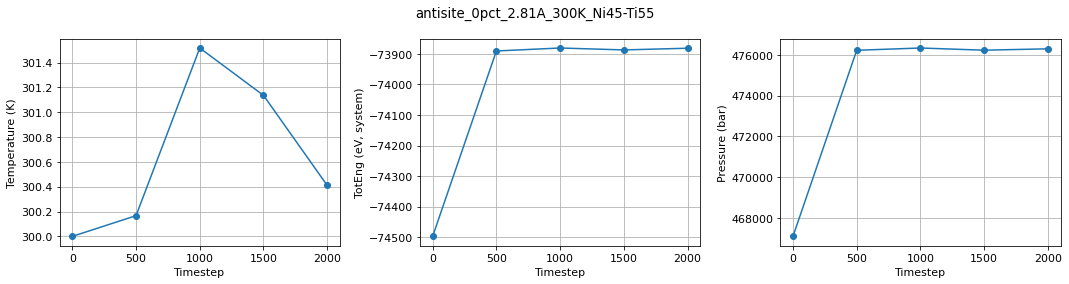

In [4]:
selected = summary.loc[summary.complete_samples].copy()
if SELECT_DEFECT_TYPE is not None:
    selected = selected.loc[selected.defect_type == SELECT_DEFECT_TYPE]
if selected.empty:
    raise ValueError('No matching complete results; adjust SELECT_DEFECT_TYPE or SAMPLE_STEPS.')
ni_choice = float(selected.ni_percent.min()) if SELECT_NI is None else SELECT_NI
selected = selected.loc[np.isclose(selected.ni_percent, ni_choice)]
if selected.empty:
    raise ValueError('No results for SELECT_NI.')
example = thermo.loc[thermo.source == selected.iloc[0].source].sort_values('Step')
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column, ylabel in zip(axes, ['Temp', ENERGY_COLUMN, 'Press'],
                             ['Temperature (K)', f'{ENERGY_COLUMN} (eV, system)', 'Pressure (bar)']):
    ax.plot(example.Step.to_numpy(), example[column].to_numpy(), 'o-')
    ax.set(xlabel='Timestep', ylabel=ylabel)
fig.suptitle(Path(selected.iloc[0].source).stem)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'thermo_history.png', dpi=160)
plt.show()


## Energy versus lattice parameter and volume
Panels correspond to available temperatures at the selected Ni concentration. Each defect level has its own curve. Incomplete curves are plotted using the available points only.

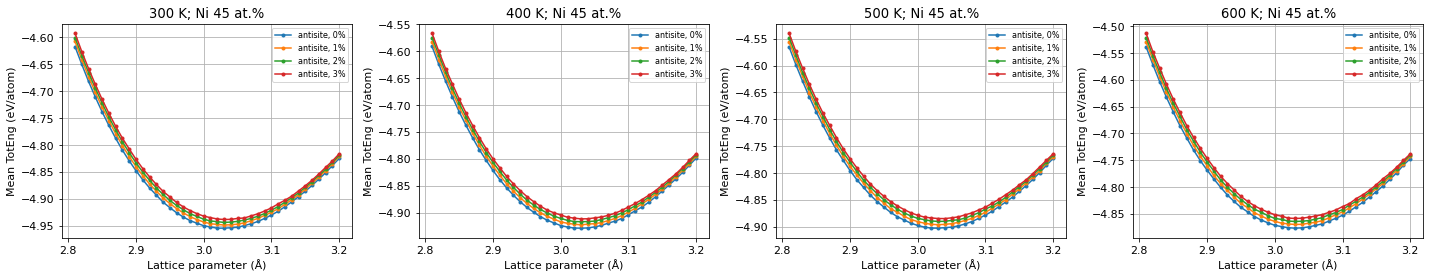

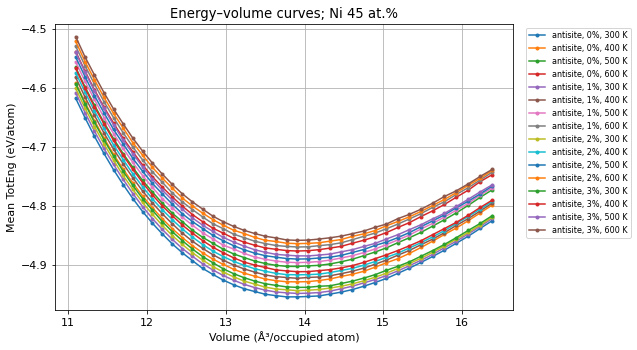

In [5]:
temperatures = sorted(selected.temperature_K.unique())
fig, axes = plt.subplots(1, len(temperatures), figsize=(5 * len(temperatures), 4), squeeze=False)
for ax, temperature in zip(axes[0], temperatures):
    for (kind, percent), group in selected.loc[selected.temperature_K == temperature].groupby(['defect_type', 'defect_percent']):
        group = group.sort_values('lattice_parameter_A')
        ax.plot(group.lattice_parameter_A.to_numpy(), group.energy_eV_atom.to_numpy(), 'o-', ms=3,
                label=f'{kind}, {percent:g}%')
    ax.set(title=f'{temperature:g} K; Ni {ni_choice:g} at.%',
           xlabel='Lattice parameter (Å)', ylabel=f'Mean {ENERGY_COLUMN} (eV/atom)')
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'energy_vs_lattice.png', dpi=160)
plt.show()

fig, ax = plt.subplots()
for (kind, percent, temperature), group in selected.groupby(['defect_type', 'defect_percent', 'temperature_K']):
    group = group.sort_values('volume_A3_atom')
    ax.plot(group.volume_A3_atom.to_numpy(), group.energy_eV_atom.to_numpy(), '.-',
            label=f'{kind}, {percent:g}%, {temperature:g} K')
ax.set(xlabel='Volume (Å³/occupied atom)', ylabel=f'Mean {ENERGY_COLUMN} (eV/atom)',
       title=f'Energy–volume curves; Ni {ni_choice:g} at.%')
ax.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'energy_vs_volume.png', dpi=160, bbox_inches='tight')
plt.show()


## Equation-of-state fits
Use the third-order Birch–Murnaghan equation with consistent volume-per-atom and energy-per-atom units. Unlike the legacy routine, do not apply an extra √2 factor to the pressure conversion. Fit only groups with at least six lattice values and an observed minimum away from the endpoints. Groups without a bracketed minimum remain in `fit_results` with a reason for skipping.

`B_energy_GPa` is the fitted energy curvature. Fit values are provisional for these short finite-temperature trajectories; no statistical uncertainty is inferred from the two correlated time samples.

In [6]:
def birch_murnaghan(volume, e0, v0, b0, bprime):
    eta = (v0 / volume)**(2 / 3)
    return e0 + 9 * v0 * b0 / 16 * ((eta - 1)**3 * bprime + (eta - 1)**2 * (6 - 4 * eta))

fit_rows = []
for keys, group in summary.loc[summary.complete_samples].groupby(GROUP):
    group = group.sort_values('volume_A3_atom')
    row = dict(zip(GROUP, keys))
    row.update(n_lattice=len(group), status='skipped', reason='')
    v, e = group.volume_A3_atom.to_numpy(), group.energy_eV_atom.to_numpy()
    if len(group) < 6:
        row['reason'] = 'Fewer than six lattice points'
    elif np.argmin(e) in (0, len(e) - 1):
        row['reason'] = 'Minimum not bracketed by sampled volumes'
    else:
        try:
            with warnings.catch_warnings():
                warnings.simplefilter('error', OptimizeWarning)
                params, covariance = curve_fit(birch_murnaghan, v, e,
                    p0=[e.min(), v[e.argmin()], 1., 4.],
                    bounds=([-np.inf, v.min(), 1e-8, 0.], [np.inf, v.max(), 20., 12.]),
                    maxfev=20000)
            e0, v0, b0, bprime = params
            if np.isclose(v0, v.min()) or np.isclose(v0, v.max()) or np.isclose(b0, 20.) or np.isclose(bprime, [0., 12.]).any():
                raise ValueError('Fit at parameter bounds')
            n = group.n_atoms.iloc[0]
            row.update(status='fitted', E0_eV_atom=e0, V0_A3_atom=v0,
                       B_energy_GPa=b0 * EV_A3_TO_GPA, Bprime=bprime,
                       lattice0_A=(v0 * n / (ORIGINAL_SITES / 2))**(1 / 3),
                       rmse_eV_atom=float(np.sqrt(np.mean((e - birch_murnaghan(v, *params))**2))))
        except (RuntimeError, ValueError, OptimizeWarning) as exc:
            row['reason'] = str(exc)
    fit_rows.append(row)
fit_results = pd.DataFrame(fit_rows)
fit_results.to_csv(OUTPUT_DIR / 'equation_of_state_fits.csv', index=False)
display(fit_results)
print(f"Fits accepted: {(fit_results.status == 'fitted').sum()} / {len(fit_results)}")


,defect_type,defect_percent,temperature_K,ni_percent,n_lattice,status,reason,E0_eV_atom,V0_A3_atom,B_energy_GPa,Bprime,lattice0_A,rmse_eV_atom
0,antisite,0,300,45.0,40,fitted,,-4.954425,13.914823,126.897653,4.288127,3.030418,0.000377
1,antisite,0,300,46.0,40,fitted,,-4.958443,13.834498,127.575299,4.270735,3.024576,0.000286
2,antisite,0,300,47.0,40,fitted,,-4.962671,13.751673,128.273113,4.277676,3.018528,0.000300
3,antisite,0,400,45.0,40,fitted,,-4.928697,13.917557,127.377311,4.233783,3.030617,0.000374
4,antisite,0,400,46.0,40,fitted,,-4.932925,13.834300,127.971813,4.247333,3.024561,0.000289
5,antisite,0,400,47.0,40,fitted,,-4.937384,13.751987,128.643098,4.252825,3.018551,0.000423
6,antisite,0,500,45.0,40,fitted,,-4.902725,13.922088,127.490086,4.183599,3.030945,0.000364
7,antisite,0,500,46.0,40,fitted,,-4.907268,13.839417,128.243390,4.197469,3.024934,0.000369
8,antisite,0,500,47.0,40,fitted,,-4.911756,13.753470,128.700447,4.251973,3.018659,0.000399
9,antisite,0,600,45.0,40,fitted,,-4.876302,13.924481,127.247004,4.181055,3.031119,0.000400


Fits accepted: 36 / 40


## Fitted properties versus Ni concentration
Plot all available concentrations, keeping defect type, percentage, and temperature separate. These figures update when additional completed NPZ files are exported.

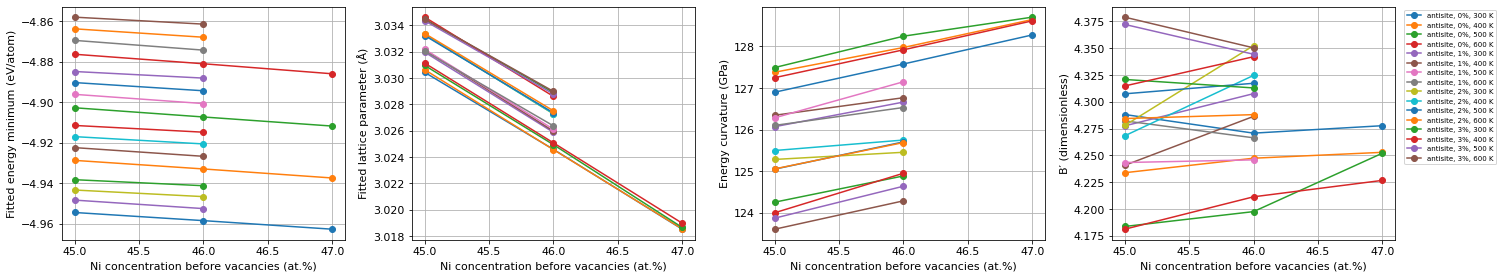

CSV tables and PNG figures saved in /home/dajuarez4/NiTi-dataset/NiTi-defect-thermodynamics/diego_dat/postprocessing


In [7]:
accepted = fit_results.loc[fit_results.status == 'fitted']
if accepted.empty:
    print('No bracketed energy minimum available yet. Inspect the energy curves and rerun when more lattice values are complete.')
else:
    fig, axes = plt.subplots(1, 4, figsize=(21, 4))
    for keys, group in accepted.groupby(['defect_type', 'defect_percent', 'temperature_K']):
        group = group.sort_values('ni_percent')
        label = f'{keys[0]}, {keys[1]:g}%, {keys[2]:g} K'
        for ax, column, ylabel in zip(axes, ['E0_eV_atom', 'lattice0_A', 'B_energy_GPa', 'Bprime'],
                                     ['Fitted energy minimum (eV/atom)', 'Fitted lattice parameter (Å)', 'Energy curvature (GPa)', "B′ (dimensionless)"]):
            ax.plot(group.ni_percent.to_numpy(), group[column].to_numpy(), 'o-', label=label)
            ax.set(xlabel='Ni concentration before vacancies (at.%)', ylabel=ylabel)
    axes[-1].legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc='upper left')
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / 'fitted_properties_vs_concentration.png', dpi=160, bbox_inches='tight')
    plt.show()
print(f'CSV tables and PNG figures saved in {OUTPUT_DIR}')


## Structure-dependent sections of the original notebook
Warren–Cowley order, configurational entropy, and the original Debye–Grüneisen workflow are not evaluated from thermo-only NPZ files. Atomic coordinates/species are required for the structural analysis; a validated thermodynamic model is required before deriving thermal properties from the fitted curves.